In [36]:
#Christian Yanez
from sklearn import datasets
import numpy as np
import warnings
warnings.warn("There is a warning here")
X, y = datasets.make_blobs(
    n_samples=400,
    n_features=5,
    centers=4,
    cluster_std=2,
    random_state=100
)
#Question 1
#Find prior probabilities
#print(X)
#print(y)#the classes of 0, 1, 2, 3
amount_y = np.bincount(y)
priors = []
print(amount_y/len(y)) #these are the prior probabilities of each class
for i in range(len(set(y))):#this has to be range set(y) because if range was set to len(y), the priors array would have a dimension of (400,)
    y_count = np.sum(y == i)
    priors.append(y_count / len(y))

#print(priors[0])#to store priors as an array for later

[0.25 0.25 0.25 0.25]


In [100]:
#Log-likelihoods under Naive Bayes
#get the mean for each class
warnings.warn("There is a warning here")
x0 = X[y==0]
x1 = X[y==1]
x2 = X[y==2]
x3 = X[y==3]
means = np.array([
    np.mean(x0, axis = 0),#must be axis=0 because classes are features, which are the columns. While rows are the entries
    np.mean(x1, axis = 0),#there are 5 features
    np.mean(x2, axis = 0),
    np.mean(x3, axis = 0)
])
for i in range(len(means)):
    print("Here are the means for class: ", i ,": " , means[i])

#now for the array of log likelihoods

#Naive Bayes:
"""
(1/(sqrt(2 * pi * variance[i]))) * e ^ (-(X - mean[i])^2)/(2*variance[i])
"""
#The mean was already found, now we need an array for the variance to then put into this equation for each class

variance = np.array([
    np.var(x0, axis = 0),
    np.var(x1, axis = 0),
    np.var(x2, axis = 0),
    np.var(x3, axis = 0)
])

#we need to find the log of Naive Bayes
log_l = np.zeros((400, 4))
for k in range(4):
    print("This is the log likelihood for k = ", k)
    log_l[:, k] = np.sum(-(1/2) * np.log(2 * np.pi * variance[k]) - ((X - means[k]) ** 2) / (2 * variance[k]), axis=1)
    #in log form, 
    print(log_l[:,k])#prints out 400 entries per k

#the first entry in each likelyhood is for the sample and depending on which array it's in which is noted by k=0, 1, 2, 3.

Here are the means for class:  0 :  [  0.8069849   -4.70373334  -1.1590356    7.2599855  -10.08546544]
Here are the means for class:  1 :  [-7.81570763  3.21413817  6.52999866 -7.18552815  1.37605939]
Here are the means for class:  2 :  [ 7.80031496 -5.39540024 -6.46872    -7.60601158 -5.51083793]
Here are the means for class:  3 :  [ 9.21561337  6.20042028 -6.59975696  6.3105034  -4.57856867]
This is the log likelihood for k =  0
[ -42.27724711  -40.22898042   -8.79382953  -34.92802553  -54.38214792
  -87.08130664  -45.32379206  -68.87094062  -66.20863249  -48.67000487
  -11.87567076  -43.12923229  -46.42115464  -42.13781282  -10.84026171
  -43.16331061  -42.81401819  -47.71400686  -78.56959983  -34.27127077
  -46.54032011  -71.92900511  -69.39892531  -43.66227187  -68.25450469
  -40.45945535  -70.2283674   -12.32045415  -42.91277047  -10.22324159
  -41.81148145  -40.39002415   -9.45435379  -11.69710247  -56.60262721
  -15.79673857  -64.38211279  -45.73114679  -76.11896885  -46.236502

In [101]:
# Class prediction via posterior maximization
#this is found by finding the argmax of the log of the priors and adding it with the log likelihood
warnings.warn("There is a warning here")
log_prior = np.log(priors)
class_prediction = np.argmax(log_prior + log_l, axis = 1)
print(class_prediction)#the class that got us the largest prediction

[3 2 0 3 3 1 3 1 2 2 0 2 2 3 0 3 2 3 1 2 2 1 1 3 1 3 1 0 2 0 2 3 0 0 3 0 1
 1 1 2 1 3 2 0 0 3 3 2 3 1 3 1 2 2 3 1 0 1 3 2 2 0 3 1 1 0 3 2 1 0 1 2 1 2
 0 0 1 1 2 0 0 1 1 0 1 0 0 3 2 1 1 3 3 0 2 1 3 2 3 1 2 2 1 1 1 1 2 3 2 3 1
 3 0 3 2 2 1 1 1 3 1 3 0 3 0 2 1 3 3 2 3 2 3 0 2 2 2 3 1 3 2 0 0 0 0 2 3 1
 3 0 0 1 3 1 2 0 0 3 0 3 1 0 0 2 0 3 1 2 2 3 0 0 3 1 1 0 3 0 0 0 1 0 1 0 1
 0 3 2 1 2 2 0 1 3 2 3 3 0 3 2 0 0 1 3 0 3 3 2 1 3 0 1 2 2 3 1 2 1 2 3 1 0
 1 3 1 0 0 1 0 0 3 0 1 0 3 1 3 3 0 0 1 3 0 0 2 1 2 2 0 3 0 0 1 3 3 2 0 0 1
 2 2 1 3 0 2 1 3 3 2 1 0 2 0 0 3 3 2 0 3 2 2 3 2 2 1 0 3 0 1 2 0 3 1 1 2 2
 0 0 2 3 1 0 2 0 0 1 0 1 1 3 2 0 1 3 3 1 3 2 2 3 2 1 1 1 1 2 2 3 2 0 0 2 2
 0 1 1 0 1 2 1 3 1 2 0 0 1 0 3 3 2 2 2 2 0 3 2 3 2 1 3 2 1 1 2 2 2 3 2 2 0
 2 0 2 0 1 2 0 3 1 3 2 1 3 3 3 3 0 3 1 0 1 0 0 2 3 1 1 3 2 3]


In [102]:
#Confusion matrix
from sklearn.metrics import confusion_matrix #import
warnings.warn("There is a warning here")
#confustion matrix accepts 2 parameters, the actual data and the predictions
cm = confusion_matrix(y, class_prediction)#rows are the actual listed class, and the columns are the results of the prediction
print(cm)

[[100   0   0   0]
 [  0 100   0   0]
 [  0   0 100   0]
 [  0   0   0 100]]


In [103]:
#Sklearn GaussianNB comparison
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score#imports
warnings.warn("There is a warning here")
model = GaussianNB()

model.fit(X, y)

y_pred = model.predict(X)

accuracy = accuracy_score(y, y_pred)

print(accuracy)

1.0


In [104]:
#Question 2
#Implement perceptron_fit
warnings.warn("There is a warning here")
X2, y2 = datasets.make_blobs(
    n_samples=400,
    n_features=5,
    centers=2,#2 classes
    cluster_std=2,
    random_state=100
)
w = np.random.rand(X2.shape[1] + 1)#initialize w randomly, according to the lecture
print(w)
y2 = np.where(y2 == 0, -1, 1)#step function for activation where -1 and 1 affect the weight
#code from the lecture slides with some adjustments

def step(X2):
    return int(1) if X2 >= 0 else int(-1)
    
def perceptron_fit(w, X2, y2, iteration):
    for j in range(iteration):
        #print(w)
        for k in range(len(y2)):
            h = perceptron_predict(w, X2, k)
            
            if h != y2[k]:
                x_with_bias = np.append(1, X2[k])
                w = w + (x_with_bias* y2[k])# [1, X[k]] * y[k] is repaced with w_with_bias to make (1,X2[k]) into a single value
                #print(w)
    return w
def perceptron_predict(w, X2, i):
    return step(np.dot(np.append(1, X2[i]), w))

#iteration = 2
#current_w = perceptron_fit(w.copy(), X2, y2, iteration)    
#prediction = perceptron_predict(current_w, X2, i)


[0.66724936 0.75045629 0.42977438 0.41794606 0.40709544 0.9201733 ]


In [105]:
#Train and evaluate the perceptron
#using sklearn.metrics.accuracy_score
warnings.warn("There is a warning here")
w = np.random.rand(X2.shape[1] + 1)    
for iteration in [1, 2, 5, 10, 20, 30, 50, 75, 100]:#let's try with different iteration counts

    current_w = perceptron_fit(w.copy(), X2, y2, iteration)#to make a w that is the adjusted w using the randomized w
    y_pred = []
    for i in range(len(y2)):
        prediction = perceptron_predict(current_w, X2, i)
        
        y_pred.append(prediction)
        
    accuracy = accuracy_score(y2, y_pred)

    print("Iteration =", iteration)
    print("w =", w)
    print("Accuracy =", accuracy, "\n")#earlier testing showed accuracy be around .56, but it was the only accuracy that was printed before implementing current_w.
    #then after some changes, accuracy would only be reported as 1.0 with no further changes to the weight

    #Explaination:
    #Accuracy keeps being 1.0, normally if the accuracy wasn't perfect, the loop would make adjustments to weight with if h!=y2[k]:
    #Then if it manages to reach 1.0 on its own, it wouldn't make any more changes after that. But seemingly it only makes 1 adjustment even when trying to put multiple print(w) to try to see individual changes


Iteration = 1
w = [0.94926491 0.07245839 0.72209113 0.15592521 0.16064379 0.69365288]
Accuracy = 1.0 

Iteration = 2
w = [0.94926491 0.07245839 0.72209113 0.15592521 0.16064379 0.69365288]
Accuracy = 1.0 

Iteration = 5
w = [0.94926491 0.07245839 0.72209113 0.15592521 0.16064379 0.69365288]
Accuracy = 1.0 

Iteration = 10
w = [0.94926491 0.07245839 0.72209113 0.15592521 0.16064379 0.69365288]
Accuracy = 1.0 

Iteration = 20
w = [0.94926491 0.07245839 0.72209113 0.15592521 0.16064379 0.69365288]
Accuracy = 1.0 

Iteration = 30
w = [0.94926491 0.07245839 0.72209113 0.15592521 0.16064379 0.69365288]
Accuracy = 1.0 

Iteration = 50
w = [0.94926491 0.07245839 0.72209113 0.15592521 0.16064379 0.69365288]
Accuracy = 1.0 

Iteration = 75
w = [0.94926491 0.07245839 0.72209113 0.15592521 0.16064379 0.69365288]
Accuracy = 1.0 

Iteration = 100
w = [0.94926491 0.07245839 0.72209113 0.15592521 0.16064379 0.69365288]
Accuracy = 1.0 



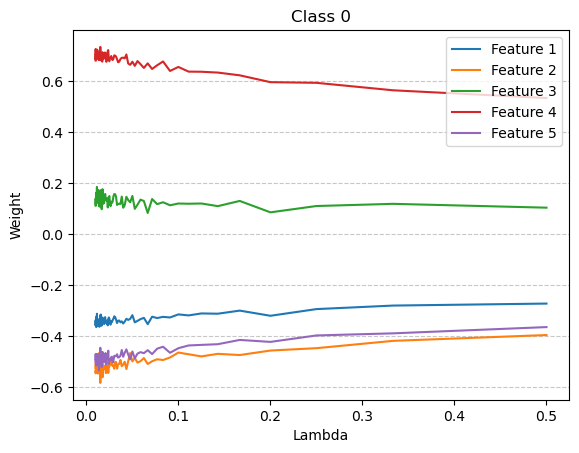

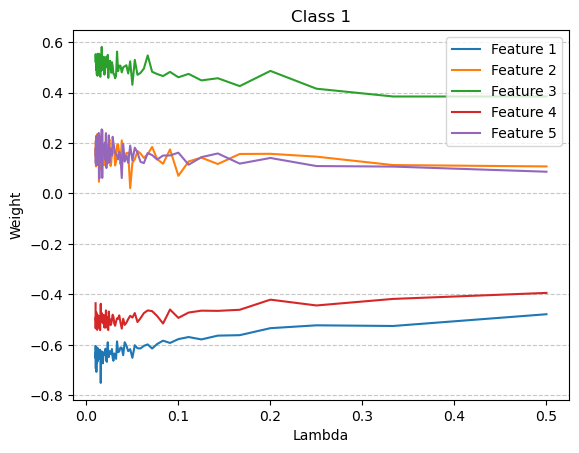

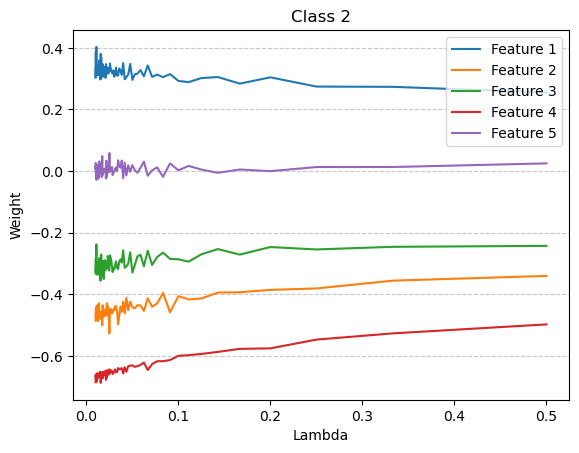

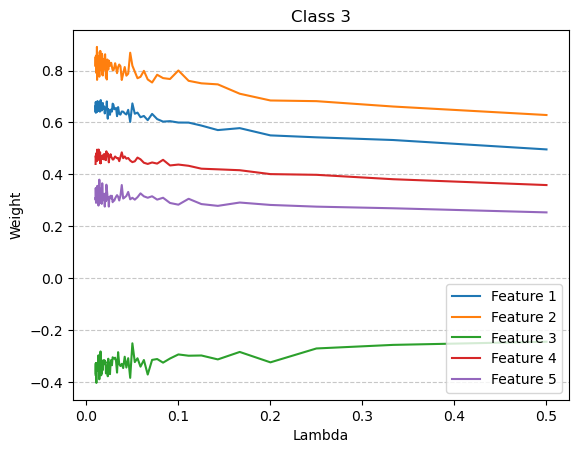

In [126]:
#Question 3
#L1 (Lasso) regularization paths

warnings.filterwarnings("default", category=DeprecationWarning)
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt#since we are plotting our results


X3, y3 = datasets.make_blobs(
    n_samples=400,
    n_features=5,
    centers=4,
    cluster_std=2,
    random_state=100
)

clf = LogisticRegression(#provided code with the recommended swap for l1
    l1_ratio=1,
    solver='saga',
    C=100.0,
    max_iter=500,
    # Avoiding reproducibility here helps to visualize convergence.
    random_state=None
)
#make C vary from 100 to 2, weak to strong penalty
C_values = np.arange(100, 1, -1)#np.array would not be a smart move to establish a range
lambda_values = 1 / C_values#since lambda is 1/C
weights = []#we are plotting weights vs lambda, 

for C in C_values:
    clf.C = C
    clf.fit(X3, y3)
    weights.append(clf.coef_)#this line solves for the w in the logistric regression. that's what coef_ does

#to plot each class, I decided to go with a for loop to cycle through the different classes that we are using
weights = np.array(weights)
#print(len(weights))#should be 99 because C is from 100 to 2.
for i in range(4):
    plt.figure()
    for j in range(5):
        plt.plot(lambda_values, weights[:, i, j],label=f"Feature {j + 1}")#To make the label for each feature appear correctly
    plt.xlabel("Lambda")
    plt.ylabel("Weight")
    plt.title(f"Class {i}")
    plt.legend()
    plt.grid(True, axis="y", linestyle="--", alpha=0.7)#to make it more clear if a feature was approaching 0 or not
    plt.show()

In [96]:
#Feature importance under L1
#Class 0
"""
Feature 3 stays the closest to 0 meaning it's weight has the least amount of sway on the regularization.
"""

#Class 1
"""
While Feature 2 and 5 appear to intersect a lot, by the time we get to lambda = 1/2, Feature 5 is approaching 0.
"""

#Class 2
"""
Feature 5 is practically at 0
"""

#Class 3
"""
Seemingly Feature 3 and Feature 5 are closest to 0, but are at least +-.2 away from 0.
They seem to be approaching 0 near the end of the lambda range, but I do not think there is enough information to draw a conclusion
"""

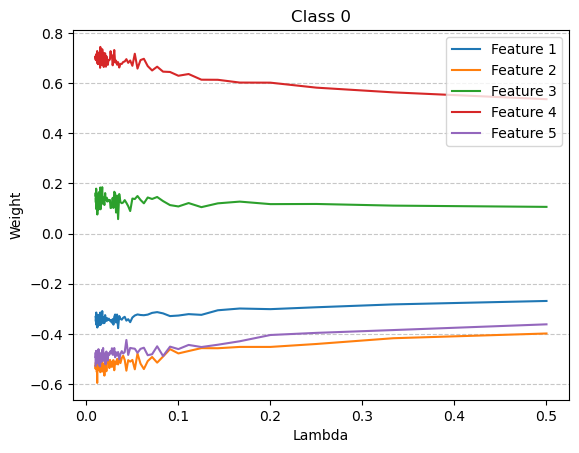

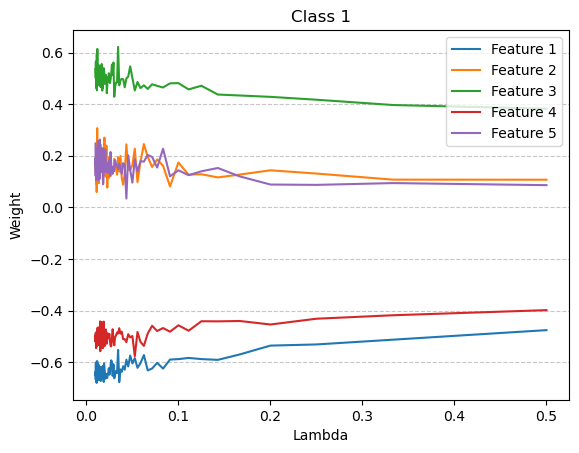

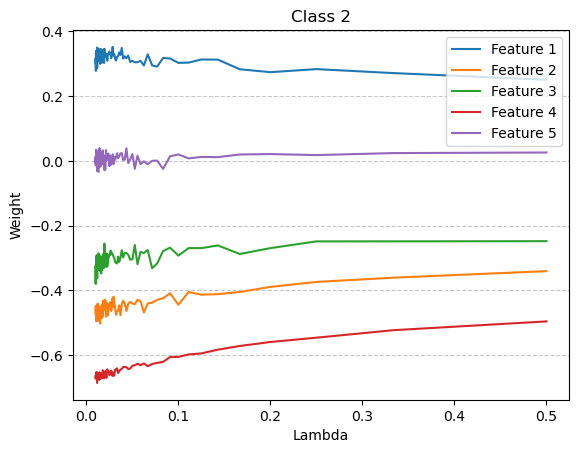

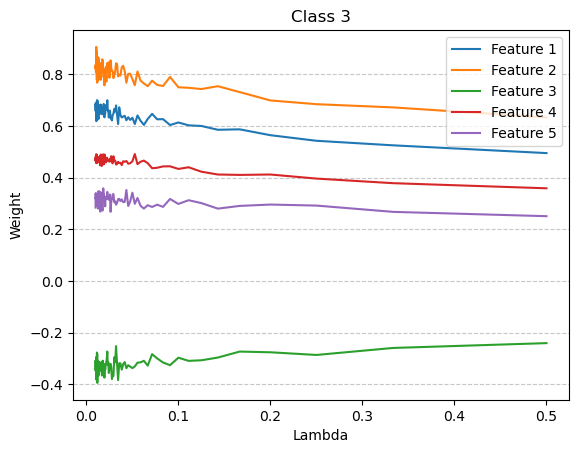

In [125]:
#L2 comparison
warnings.filterwarnings("default", category=DeprecationWarning)
clf2 = LogisticRegression(#provided code with the recommended swap for l2
    l1_ratio=0,
    solver='saga',
    C=100.0,
    max_iter=500,
    # Avoiding reproducibility here helps to visualize convergence.
    random_state=None
)

C_values2 = np.arange(100, 1, -1)
lambda_values2 = 1 / C_values2
weights2 = []

for C in C_values:
    clf2.C = C
    clf2.fit(X3, y3)
    weights2.append(clf2.coef_)

weights2 = np.array(weights2)
for i in range(4):
    plt.figure()
    for j in range(5):
        plt.plot(lambda_values2, weights2[:, i, j],label=f"Feature {j + 1}")
    plt.xlabel("Lambda")
    plt.ylabel("Weight")
    plt.title(f"Class {i}")
    plt.legend()
    plt.grid(True, axis="y", linestyle="--", alpha=0.7)
    plt.show()

In [ ]:
"""
The behavior of both regularizations appear to be similar to each other, one of the known differences between L1 and L2 is
that L2 will never truly reach 0. L1 has weights that will eventually reach 0, which leads to sparse solutions and some features 
being ignored by the model. In L2 I so notice that in Class 2, Feature 5 avoids reaching 0 at a sharper slope as Lambda increases.
"""